# 05 - Improved logistic purchase probability
Predict `purchase_14d` using the 43 registered pre-send predictors. Purchase probability describes the historical mixture of offers; it is neither treatment assignment propensity nor an untreated response probability.

The model remains logistic regression. We compare raw predictors, signed log transforms, selected behavioral interactions, and spline bases, with regularization. Development uses forward validation on CP04, CP05, and CP06, each trained only on earlier campaigns. The configuration is frozen before CP07 scoring. CP07 was inspected in the earlier audit, so this is retrospective confirmation, **not a fresh untouched holdout**. A future campaign is still needed for prospective confirmation.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve
from src.common import TABLES, FIGS, MODELS, load_processed
from src.modeling import feature_lists, make_propensity_pipe
from src.propensity import fit_purchase_model, select_purchase_config, purchase_metrics, PURCHASE_SELECTION_RULE
from scripts.experiment_propensity import paired_purchase_intervals
pd.set_option("display.width", 200)
df = load_processed("historical_feature_outcome")
NUM, CAT = feature_lists(); X_COLS = NUM + CAT
outcomes = set(pd.read_csv(TABLES / "outcome_schema.csv").outcome)
FORBIDDEN = {"assignment_id", "customer_id", "campaign_id", "send_ts", "outcome_end_ts", "assignment_source", "offer_type", "email_delivered"} | outcomes
assert not set(X_COLS) & FORBIDDEN, set(X_COLS) & FORBIDDEN
development = df[df.campaign_id.lt("CP07")]
test = df[df.campaign_id.eq("CP07")]
print(f"{len(NUM)} numeric + {len(CAT)} categorical = {len(X_COLS)} raw predictors")
df.groupby("campaign_id").purchase_14d.agg(["size", "mean"])


36 numeric + 7 categorical = 43 raw predictors


,size,mean
campaign_id,,
CP01,3800,0.130526
CP02,3800,0.131053
CP03,3800,0.126842
CP04,3800,0.129737
CP05,3800,0.121579
CP06,3800,0.138158
CP07,3800,0.131842


## Development selection and saved configuration
Sixteen configurations cover four scientifically motivated feature sets and four regularization strengths. Choose the highest mean average precision (reported as PR-AUC) across the three forward folds, with log loss and Brier guardrails against the original model; ROC-AUC breaks ties. Then try a sigmoid recalibration fitted only from earlier out-of-time predictions. Keep it only if both probability losses improve. PR-AUC assesses ranking among relatively rare purchasers; log loss and Brier assess the probability estimates used downstream. The development scores are used for selection and are therefore not unbiased estimates of the selected model's performance.

In [2]:
CONFIG, development_folds, development_summary = select_purchase_config(
    development, NUM, CAT, validation_campaigns=["CP04", "CP05", "CP06"])
development_folds.to_csv(TABLES / "logistic_validation_folds.csv", index=False)
development_summary.to_csv(TABLES / "logistic_validation_grid.csv", index=False)
selection = {"config": CONFIG, "validation_campaigns": ["CP04", "CP05", "CP06"],
             "selection_rule": PURCHASE_SELECTION_RULE,
             "cp07_status": "Previously inspected; retrospective confirmation only"}
(TABLES / "logistic_selected_config.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
print("Frozen configuration:", CONFIG)
print(PURCHASE_SELECTION_RULE)
development_summary.round(6)


Frozen configuration: {'mode': 'log_interactions', 'C': 0.01, 'calibration': 'none'}
maximize mean out-of-time PR-AUC with log_loss <= original + .001 and Brier <= original + .0005; ROC-AUC tie-break. Select nested temporal sigmoid only if both log-loss and Brier improve.


,mode,C,calibration,roc_auc,pr_auc,log_loss,brier
5,log_interactions,0.010,none,0.670643,0.235397,0.364494,0.107658
6,log_interactions,0.010,sigmoid,0.670643,0.235397,0.366494,0.108153
1,log,0.010,none,0.671791,0.234152,0.364499,0.107693
14,raw,0.010,none,0.671119,0.233733,0.364775,0.107773
4,log_interactions,0.001,none,0.668320,0.233001,0.367425,0.108393
7,log_interactions,0.100,none,0.666956,0.232157,0.365840,0.108038
2,log,0.100,none,0.668750,0.231284,0.365500,0.107986
15,raw,0.100,none,0.667248,0.230150,0.365896,0.108096
3,log,1.000,none,0.665546,0.229381,0.366695,0.108298
8,log_interactions,1.000,none,0.663619,0.228911,0.367175,0.108409


## Development-only threshold
The F1 threshold is estimated from the selected configuration's pooled out-of-time CP04-CP06 predictions, before CP07 evaluation. It is an illustrative classification threshold, not an optimal promotion-profit rule. A threshold of 0.50 is retained for compatibility and is inappropriate as the sole model-quality assessment at this low purchase rate.

In [3]:
def metrics(y, p, threshold=.5):
    y = np.asarray(y); p = np.asarray(p); yh = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {**purchase_metrics(y, p), "threshold": threshold,
            "precision": precision_score(y, yh, zero_division=0),
            "recall": recall_score(y, yh, zero_division=0), "f1": f1_score(y, yh, zero_division=0),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp, "base_rate": y.mean(), "mean_pred": p.mean()}

validation_predictions = []
for campaign in ["CP04", "CP05", "CP06"]:
    earlier = development[development.campaign_id.lt(campaign)]
    held = development[development.campaign_id.eq(campaign)]
    fitted = fit_purchase_model(earlier, NUM, CAT, CONFIG)
    validation_predictions.append(held[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(
        predicted_purchase_probability=fitted.predict_proba(held[X_COLS])[:, 1]))
validation_predictions = pd.concat(validation_predictions, ignore_index=True)
validation_predictions.to_csv(TABLES / "logistic_development_predictions.csv", index=False)
pr, rc, thresholds = precision_recall_curve(validation_predictions.purchase_14d, validation_predictions.predicted_purchase_probability)
F1_THR = float(thresholds[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))])
print("Development F1 threshold:", round(F1_THR, 6))


Development F1 threshold: 0.15878


## Retrospective CP07 comparison
The fair comparison refits both the original raw-feature logistic model and the selected model on CP01-CP06. The previously published model used only CP01-CP05 for its CP07 evaluation; that result is reproduced separately so gains from extra training data are not confused with gains from feature engineering. No configuration is changed in response to CP07.

In [4]:
original_published = make_propensity_pipe(NUM, CAT, C=.01).fit(
    df.loc[df.campaign_id.lt("CP06"), X_COLS], df.loc[df.campaign_id.lt("CP06"), "purchase_14d"])
original_refit = make_propensity_pipe(NUM, CAT, C=.01).fit(development[X_COLS], development.purchase_14d)
model = fit_purchase_model(development, NUM, CAT, CONFIG)
yte = test.purchase_14d.to_numpy()
p_published = original_published.predict_proba(test[X_COLS])[:, 1]
p_original = original_refit.predict_proba(test[X_COLS])[:, 1]
p_te = model.predict_proba(test[X_COLS])[:, 1]
comparison = pd.DataFrame([
    {"model": "original_published_reproduced", "training_campaigns": "CP01-CP05", **purchase_metrics(yte, p_published)},
    {"model": "original_fair_refit", "training_campaigns": "CP01-CP06", **purchase_metrics(yte, p_original)},
    {"model": "selected", "training_campaigns": "CP01-CP06", **purchase_metrics(yte, p_te)}])
comparison.to_csv(TABLES / "logistic_cp07_comparison.csv", index=False)
vp = validation_predictions.query("campaign_id == 'CP06'")
res = pd.DataFrame([
    {"split": "valid_CP06", **metrics(vp.purchase_14d, vp.predicted_purchase_probability)},
    {"split": "test_CP07", **metrics(yte, p_te)},
    {"split": "valid_CP06_f1thr", **metrics(vp.purchase_14d, vp.predicted_purchase_probability, F1_THR)},
    {"split": "test_CP07_f1thr", **metrics(yte, p_te, F1_THR)}])
res.insert(1, "C", CONFIG["C"]); res.insert(2, "feature_mode", CONFIG["mode"])
res.to_csv(TABLES / "logistic_metrics.csv", index=False)
comparison.round(6)


,model,training_campaigns,roc_auc,pr_auc,log_loss,brier,observed_mean,predicted_mean
0,original_published_reproduced,CP01-CP05,0.654933,0.230630,0.372566,0.109969,0.131842,0.124697
1,original_fair_refit,CP01-CP06,0.658743,0.232325,0.371117,0.109704,0.131842,0.128900
2,selected,CP01-CP06,0.658879,0.236708,0.370689,0.109558,0.131842,0.130602


## Uncertainty in the improvement
Paired bootstrap draws resample customers and retain both models' predictions in each draw. Intervals describe CP07 sampling uncertainty conditional on fitted models; they do not include model-selection or future campaign drift uncertainty. An observed gain with a confidence interval spanning zero is modest evidence, not proof of improvement on future campaigns.

In [5]:
paired = pd.concat([
    test[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(model="original", prediction=p_original),
    test[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(model="selected", prediction=p_te)], ignore_index=True)
paired.to_csv(TABLES / "logistic_paired_test_predictions.csv", index=False)
intervals = paired_purchase_intervals(paired, n_bootstrap=2000, seed=42)
intervals.to_csv(TABLES / "logistic_cp07_paired_bootstrap.csv", index=False)
intervals.round(6)


,metric,original,selected,difference_selected_minus_original,ci_low,ci_high,better_direction,bootstrap_draws,bootstrap_unit
0,roc_auc,0.658743,0.658879,0.000137,-0.003282,0.003544,higher,2000,customer
1,pr_auc,0.232325,0.236708,0.004384,-0.004445,0.013209,higher,2000,customer
2,log_loss,0.371117,0.370689,-0.000428,-0.001447,0.000582,lower,2000,customer
3,brier,0.109704,0.109558,-0.000146,-0.000478,0.000197,lower,2000,customer


## Ranking and calibration diagnostics
The plots compare original and selected probabilities on the same CP07 population. Decile 1 contains the highest predicted purchase probabilities. These predictions do not identify which offer changes a customer's behavior.

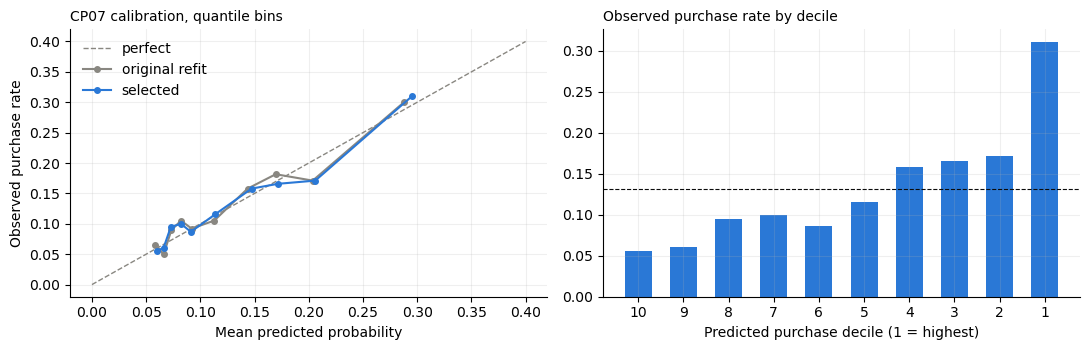

,n,purchase_rate,mean_pred,lift
decile,,,,
10,380,0.055,0.060,0.419
9,380,0.061,0.066,0.459
8,380,0.095,0.073,0.719
7,380,0.100,0.082,0.758
6,380,0.087,0.091,0.659
5,380,0.116,0.114,0.878
4,380,0.158,0.147,1.198
3,380,0.166,0.171,1.257
2,380,0.171,0.206,1.297


In [6]:
te = test[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(predicted_purchase_probability=p_te)
te.to_csv(TABLES / "logistic_test_predictions.csv", index=False)
te["decile"] = pd.qcut(te.predicted_purchase_probability.rank(method="first"), 10, labels=range(10, 0, -1))
lift = te.groupby("decile", observed=True).agg(n=("purchase_14d", "size"), purchase_rate=("purchase_14d", "mean"),
                                             mean_pred=("predicted_purchase_probability", "mean")).sort_index()
lift["lift"] = lift.purchase_rate / te.purchase_14d.mean()
lift.to_csv(TABLES / "logistic_test_decile_lift.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
limit = .4
ax[0].plot([0, limit], [0, limit], color="#898781", lw=1, ls="--", label="perfect")
for label, probability, color in [("original refit", p_original, "#898781"), ("selected", p_te, "#2a78d6")]:
    observed, predicted = calibration_curve(yte, probability, n_bins=10, strategy="quantile")
    ax[0].plot(predicted, observed, marker="o", ms=4, lw=1.5, color=color, label=label)
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Observed purchase rate")
ax[0].legend(frameon=False); ax[0].set_title("CP07 calibration, quantile bins", loc="left", fontsize=10)
ax[1].bar(lift.index.astype(str), lift.purchase_rate, color="#2a78d6", width=.6)
ax[1].axhline(te.purchase_14d.mean(), color="#0b0b0b", lw=.8, ls="--")
ax[1].set_xlabel("Predicted purchase decile (1 = highest)")
ax[1].set_title("Observed purchase rate by decile", loc="left", fontsize=10)
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIGS / "05_logistic_calibration_lift.png", bbox_inches="tight"); plt.show()
lift.round(3)


## Model interpretation and July scoring artifact
Coefficients are conditional associations on transformed, standardized, and one-hot features; correlated predictors and interactions prevent interpreting them as causal effects. After evaluation, refit the frozen configuration on CP01-CP07 for July scoring. The refit uses CP07 labels only after the comparison and is not used to evaluate CP07.

In [7]:
base = getattr(model, "base", model)
coef = pd.Series(base.named_steps["lr"].coef_[0], index=base.named_steps["pre"].get_feature_names_out()).sort_values()
coef.rename("coefficient").to_csv(TABLES / "logistic_coefficients.csv")
display(pd.concat([coef.head(8), coef.tail(8)]).round(3).to_frame("coefficient"))
final = fit_purchase_model(df, NUM, CAT, CONFIG)
joblib.dump(final, MODELS / "logistic_propensity_model.joblib")
final_base = getattr(final, "base", final)
spec = {"target": "purchase_14d", "C": CONFIG["C"], "configuration": CONFIG,
        "numeric_features": NUM, "categorical_features": CAT,
        "encoded_features": final_base.named_steps["pre"].get_feature_names_out().tolist(),
        "train_campaigns_final": sorted(df.campaign_id.unique()),
        "validation_campaigns": ["CP04", "CP05", "CP06"],
        "evaluation_fit_campaigns": sorted(development.campaign_id.unique()),
        "evaluation_campaigns": ["CP07"], "evaluation_status": "retrospective; CP07 was previously inspected",
        "selection_rule": PURCHASE_SELECTION_RULE, "f1_threshold_from_valid": F1_THR,
        "probability_interpretation": "purchase under historical treatment mixture, not untreated purchase probability"}
(MODELS / "logistic_model_features.json").write_text(json.dumps(spec, indent=2), encoding="utf-8")
reloaded = joblib.load(MODELS / "logistic_propensity_model.joblib")
np.testing.assert_allclose(reloaded.predict_proba(test[X_COLS]), final.predict_proba(test[X_COLS]))
assert np.isfinite(res[["roc_auc", "pr_auc", "log_loss", "brier"]].values).all()
print(f"Saved + reloaded: {len(X_COLS)} raw predictors -> {len(spec['encoded_features'])} encoded features")


,coefficient
cat__customer_tier_Standard,-0.432
cat__tier_membership_Standard_0,-0.236
cat__tier_membership_Standard_1,-0.196
num__preferred_matches_browse,-0.133
num__missingindicator_days_since_last_email_click,-0.086
num__missingindicator_session_recency_intensity,-0.075
num__missingindicator_days_since_last_session,-0.075
cat__preferred_category_Accessories,-0.072
cat__customer_tier_Silver,0.057
cat__top_category_viewed_30d_Apparel,0.058


Saved + reloaded: 43 raw predictors -> 103 encoded features
